<a href="https://colab.research.google.com/github/sylle321/Hotel_booking/blob/main/Descriptive_question.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px                          # interactive plots (pre-installed on Colab)
from sklearn.preprocessing import StandardScaler     # does the scaling for us
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from tqdm import tqdm

path = "/content/hotels.csv"
df = pd.read_csv(path)
#Shows each columns data type and number of non-null values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
#Counts distinct values in each column of the dataframe.
df.nunique()

,0
hotel,2
is_canceled,2
lead_time,479
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,17
stays_in_week_nights,35
adults,14


In [20]:
# Convert hotel to a dummy variable:
# Resort Hotel = 0, City Hotel = 1
df['hotel'] = df['hotel'].map({
    'Resort Hotel': 0,
    'City Hotel': 1
})

df.head()

# Create dummy variables for the other categorical variables
categorical_cols = [
    'deposit_type',
    'market_segment',
    'customer_type',
    'reserved_room_type'
]

df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 49 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  int64  
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [21]:
# Selecting the columns of interest for analysis
# Making sure unrelated columns are not included in the analysis.
cols = [
    "hotel",
    "is_canceled",
    "lead_time",
    "deposit_type",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "customer_type",
    "booking_changes",
    "is_repeated_guest",
    "market_segment",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "reserved_room_type",
    "adr",
    "distribution_channel",
    "arrival_date_month"
]

hotel_selected = df[cols]

hotel_selected.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 17 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  int64  
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   deposit_type                    119390 non-null  object 
 4   previous_cancellations          119390 non-null  int64  
 5   previous_bookings_not_canceled  119390 non-null  int64  
 6   customer_type                   119390 non-null  object 
 7   booking_changes                 119390 non-null  int64  
 8   is_repeated_guest               119390 non-null  int64  
 9   market_segment                  119390 non-null  object 
 10  total_of_special_requests       119390 non-null  int64  
 11  stays_in_weekend_nights         119390 non-null  int64  
 12  stays_in_week_ni

In [22]:
#Cleaning the data by removing rows with any missing values and resetting the index.
hotel_clean = hotel_selected.dropna(how="any") #Removes rows with any missing values.
hotel_clean = hotel_clean.reset_index(drop=True) #resets the index

print(hotel_selected.shape)
print(hotel_clean.shape)

(119390, 17)
(119390, 17)


In [23]:
#Checking cancelation counts and proportions in the cleaned dataset.
print(hotel_clean["is_canceled"].value_counts()) #Gives the count of each unique value in the "is_canceled" column.

print(
    hotel_clean["is_canceled"].value_counts(normalize=True) # Gives the proportion of each unique value in the "is_canceled" column.
)


is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64


In [24]:
# Calculate the correlation using PCA lab's code as reference.
# We exclude categorical string columns and only keep truly numeric columns
numeric_cols = [
    "is_canceled",
    "lead_time",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "is_repeated_guest",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adr"
]

hotel_numeric = hotel_clean[numeric_cols]

corr_mat = hotel_numeric.corr()

corr_mat.round(4)

,is_canceled,lead_time,previous_cancellations,previous_bookings_not_canceled,booking_changes,is_repeated_guest,total_of_special_requests,stays_in_weekend_nights,stays_in_week_nights,adr
is_canceled,1.0000,0.2931,0.1101,-0.0574,-0.1444,-0.0848,-0.2347,-0.0018,0.0248,0.0476
lead_time,0.2931,1.0000,0.0860,-0.0735,0.0001,-0.1244,-0.0957,0.0857,0.1658,-0.0631
previous_cancellations,0.1101,0.0860,1.0000,0.1527,-0.0270,0.0823,-0.0484,-0.0128,-0.0140,-0.0656
previous_bookings_not_canceled,-0.0574,-0.0735,0.1527,1.0000,0.0116,0.4181,0.0378,-0.0427,-0.0487,-0.0721
booking_changes,-0.1444,0.0001,-0.0270,0.0116,1.0000,0.0121,0.0528,0.0633,0.0962,0.0196
is_repeated_guest,-0.0848,-0.1244,0.0823,0.4181,0.0121,1.0000,0.0131,-0.0872,-0.0972,-0.1343
total_of_special_requests,-0.2347,-0.0957,-0.0484,0.0378,0.0528,0.0131,1.0000,0.0727,0.0682,0.1722
stays_in_weekend_nights,-0.0018,0.0857,-0.0128,-0.0427,0.0633,-0.0872,0.0727,1.0000,0.4990,0.0493
stays_in_week_nights,0.0248,0.1658,-0.0140,-0.0487,0.0962,-0.0972,0.0682,0.4990,1.0000,0.0652
adr,0.0476,-0.0631,-0.0656,-0.0721,0.0196,-0.1343,0.1722,0.0493,0.0652,1.0000


In [25]:
# Correlation with is_canceled only
corr_mat[["is_canceled"]].round(3)

,is_canceled
is_canceled,1.000
lead_time,0.293
previous_cancellations,0.110
previous_bookings_not_canceled,-0.057
booking_changes,-0.144
is_repeated_guest,-0.085
total_of_special_requests,-0.235
stays_in_weekend_nights,-0.002
stays_in_week_nights,0.025
adr,0.048


In [45]:
# Standardization (0 mean, unit variance)
scaler = StandardScaler()
scaled_df = pd.DataFrame(
    scaler.fit_transform(hotel_clean[pca_cols]),
    columns=pca_cols
)
scaled_df.head()


,lead_time,previous_cancellations,previous_bookings_not_canceled,booking_changes,is_repeated_guest,total_of_special_requests,stays_in_weekend_nights,stays_in_week_nights,adr
0,2.227051,-0.10318,-0.091555,4.260101,-0.18156,-0.720694,-0.92889,-1.310240,-2.015038
1,5.923385,-0.10318,-0.091555,5.793131,-0.18156,-0.720694,-0.92889,-1.310240,-2.015038
2,-0.907814,-0.10318,-0.091555,-0.338990,-0.18156,-0.720694,-0.92889,-0.786207,-0.530935
3,-0.851667,-0.10318,-0.091555,-0.338990,-0.18156,-0.720694,-0.92889,-0.786207,-0.530935
4,-0.842309,-0.10318,-0.091555,-0.338990,-0.18156,0.540666,-0.92889,-0.262174,-0.075810


In [46]:
# PCA
pcs = PCA(n_components=9)
scores = pcs.fit_transform(scaled_df)
# Naming the components PC1...PC9
pc_names = ['PC' + str(i+1) for i in range(pcs.n_components_)]
scores_df = pd.DataFrame(scores, columns=pc_names)
# Eigenvalues
eig = pcs.explained_variance_
# PCA summary table
summary_df = pd.DataFrame({
    'Eigenvalue': eig,
    '% of variance': pcs.explained_variance_ratio_ * 100,
    'Cumulative %': np.cumsum(pcs.explained_variance_ratio_) * 100
}, index=pc_names)
summary_df.round(3)


,Eigenvalue,% of variance,Cumulative %
PC1,1.734,19.268,19.268
PC2,1.393,15.473,34.741
PC3,1.273,14.140,48.881
PC4,0.990,11.003,59.884
PC5,0.944,10.490,70.374
PC6,0.816,9.061,79.435
PC7,0.793,8.806,88.241
PC8,0.567,6.295,94.537
PC9,0.492,5.463,100.000


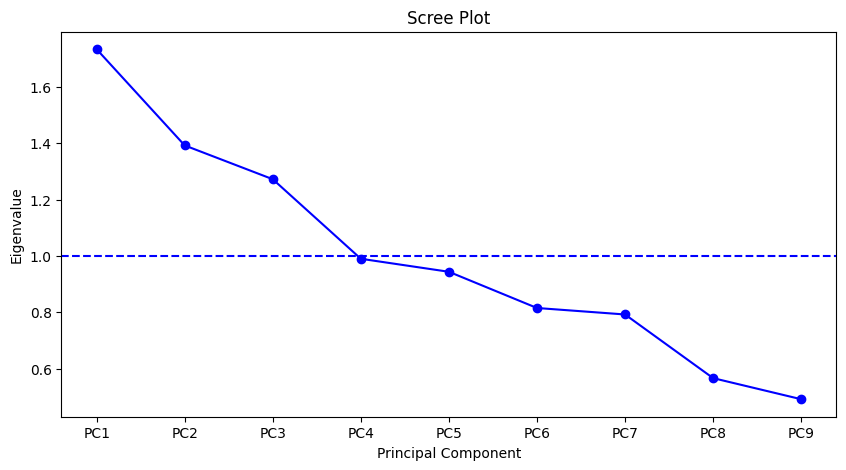

In [47]:
# Scree plot of eigenvalues
ax = summary_df['Eigenvalue'].plot(marker='o', color='blue', figsize=(10,5))
ax.axhline(y=1, color='b', linestyle='--')

ax.set_title('Scree Plot')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Eigenvalue');


In [48]:
# Component matrix (correlations)
component_matrix = pd.DataFrame(
    pcs.components_.T * np.sqrt(eig),
    index=scaled_df.columns,
    columns=pc_names
)
component_matrix.round(3)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
lead_time,0.312,0.081,-0.590,-0.131,0.287,0.607,0.260,0.050,-0.096
previous_cancellations,-0.198,0.332,-0.356,-0.509,0.489,-0.373,-0.282,0.086,0.014
previous_bookings_not_canceled,-0.502,0.630,0.106,-0.081,-0.027,0.089,0.244,-0.515,0.006
booking_changes,0.153,0.227,0.189,0.684,0.642,-0.089,0.008,-0.008,-0.034
is_repeated_guest,-0.576,0.546,0.118,0.100,-0.159,0.110,0.167,0.530,-0.023
total_of_special_requests,0.142,0.161,0.657,-0.256,0.142,0.464,-0.470,0.010,-0.002
stays_in_weekend_nights,0.649,0.491,-0.010,-0.003,-0.273,-0.185,-0.066,-0.005,-0.474
stays_in_week_nights,0.684,0.492,-0.058,0.011,-0.163,-0.059,0.036,0.037,0.504
adr,0.287,-0.146,0.549,-0.404,0.252,-0.164,0.576,0.090,-0.032
